# 🚀 **Detecção de Objetos com YOLOv8**
Este script utiliza a biblioteca Ultralytics para realizar a detecção automática de objetos em imagens. O processo segue este fluxo:
- **Upload**: Solicita um arquivo de imagem local através do Google Colab Files.
- **Configuração**: Define o modelo YOLOv8s (versão otimizada para velocidade) e ajusta o limiar de confiança para a detecção.
- **Processamento**: A IA processa a imagem, identifica os objetos e desenha as caixas delimitadoras.
- **Exibição**: Utiliza OpenCV e Matplotlib para tratar e exibir o resultado final diretamente na tela.

In [ ]:
# -------------------------------------------------------------------------
# PASSO 1: Instalação da ferramenta oficial do YOLOv8
# -------------------------------------------------------------------------
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 11.6 MB/s eta 0:00:00


Selecione sua imagem:


Saving dog bike.jpg to dog bike (1).jpg

image 1/1 /content/dog bike (1).jpg: 480x640 1 bicycle, 1 truck, 1 dog, 491.8ms
Speed: 6.0ms preprocess, 491.8ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)
Imagem processada


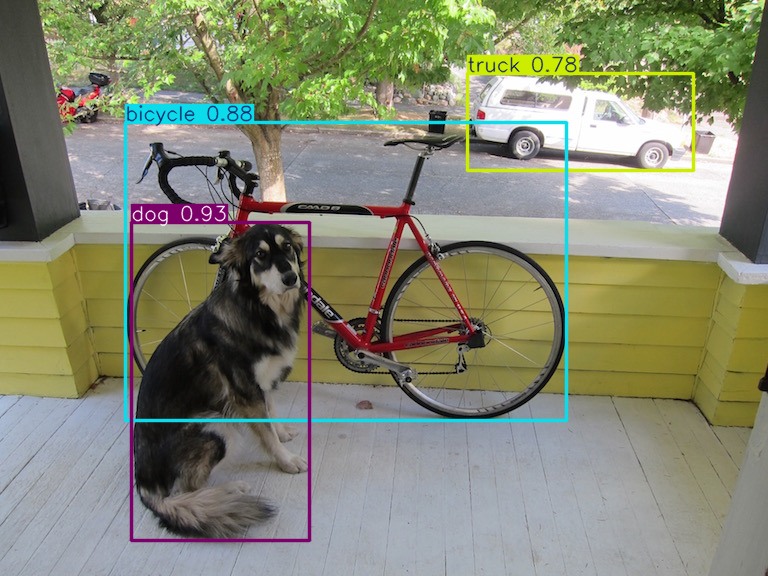

Detecção concluída com sucesso!


In [ ]:
from ultralytics import YOLO
from google.colab import files
from PIL import Image
import cv2
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

# -------------------------------------------------------------------------
# PASSO 2: Upload da Imagem
# -------------------------------------------------------------------------
print("Selecione sua imagem:")
uploaded = files.upload()
nome_do_arquivo = list(uploaded.keys())[0]

# -------------------------------------------------------------------------
# PASSO 3: Parâmetros Ajustáveis (Onde você pratica!)
# -------------------------------------------------------------------------

# Nível de certeza (0.1 a 1.0).
# Tente mudar para 0.25 para ver se ele detecta mais coisas "escondidas".
MINIMA_CONFIANCA = 0.5

# Cor da caixa (em formato RGB).
# Exemplo: (255, 0, 0) é Vermelho puro. (0, 255, 0) é Verde.
COR_DA_CAIXA = (0, 255, 0)

# -------------------------------------------------------------------------
# PASSO 4: Executando a IA
# -------------------------------------------------------------------------

# Carregamos o modelo "Small" (pequeno), que é ótimo para o Colab
modelo = YOLO('yolov8s.pt')

# A IA faz a detecção aqui
resultados = modelo.predict(source=nome_do_arquivo, conf=MINIMA_CONFIANCA)

# -------------------------------------------------------------------------
# PASSO 5: Visualização Amigável
# -------------------------------------------------------------------------
# O YOLOv8 já tem uma função pronta para desenhar os resultados
resultado_plotado = resultados[0].plot(line_width=2, font_size=12)

# # Converter de BGR para RGB para exibir corretamente
print("Imagem processada")
cv2_imshow(resultado_plotado)

print("Detecção concluída com sucesso!")

In [ ]:
# -------------------------------------------------------------------------
# PASSO 6: Listando os Objetos (Extração de Dados)
# -------------------------------------------------------------------------

# O objeto 'resultados' contém tudo o que a IA encontrou.
# Vamos percorrer cada detecção para extrair o nome da classe.

print("--- RELATÓRIO DE DETECÇÃO ---")

# Pegamos o primeiro resultado (da nossa única imagem)
res = resultados[0]

# Criamos uma lista para guardar os nomes encontrados
objetos_detectados = []

# Percorremos as 'caixas' (boxes) encontradas
for box in res.boxes:
    # Pegamos o ID da classe (um número)
    classe_id = int(box.cls[0])

    # Traduzimos o número para o nome (ex: 0 vira 'pessoa')
    nome_objeto = res.names[classe_id]

    # Pegamos a confiança (o quanto a IA tem certeza, de 0 a 1)
    confianca = float(box.conf[0])

    objetos_detectados.append(nome_objeto)
    print(f"Detectado: {nome_objeto} (Confiança: {confianca:.2%})")

# -------------------------------------------------------------------------
# PASSO 7: Resumo Geral
# -------------------------------------------------------------------------
from collections import Counter

# O Counter conta quantas vezes cada objeto apareceu
contagem = Counter(objetos_detectados)

print("\n--- RESUMO DA CONTAGEM ---")
for objeto, quantidade in contagem.items():
    print(f"{objeto.capitalize()}: {quantidade}")

--- RELATÓRIO DE DETECÇÃO ---
Detectado: dog (Confiança: 92.72%)
Detectado: bicycle (Confiança: 88.27%)
Detectado: truck (Confiança: 77.63%)

--- RESUMO DA CONTAGEM ---
Dog: 1
Bicycle: 1
Truck: 1
